--- Question 1 ---


C:\cygwin64\tmp\ipykernel_60852\4165288386.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = q1_df.select_dtypes(include=['object']).columns


Final shape of q1_df: (1617, 46)
Total missing values remaining: 0

--- Question 2 ---
Before standardization:
Smoking_Status
Never Smoked      881
Current Smoker    309
Former Smoker     149
NEVER SMOKED       40
never smoked       39
Non-Smoker         29
Never              27
Nonsmoker          25
nEVER sMOKED       23
current smoker     17
CURRENT SMOKER     13
Smoker             12
Current            10
Ex-Smoker           9
Active Smoker       8
cURRENT sMOKER      8
former smoker       5
FORMER SMOKER       5
Former              3
Ex Smoker           3
fORMER sMOKER       2
Name: count, dtype: int64

After standardization:
Smoking_Status
Never Smoked      1064
Current Smoker     377
Former Smoker      164
ex-smoker            9
ex smoker            3
Name: count, dtype: int64 

--- Question 3 ---
Stats for Tumor_Size_cm:
Mean: 4.57
Median: 4.30
Std Dev: 2.34
Min: 0.50
Max: 13.30

Stats for BMI:
Mean: 26.55
Median: 26.50
Std Dev: 4.10
Min: 16.00
Max: 40.00

Full statistical summa

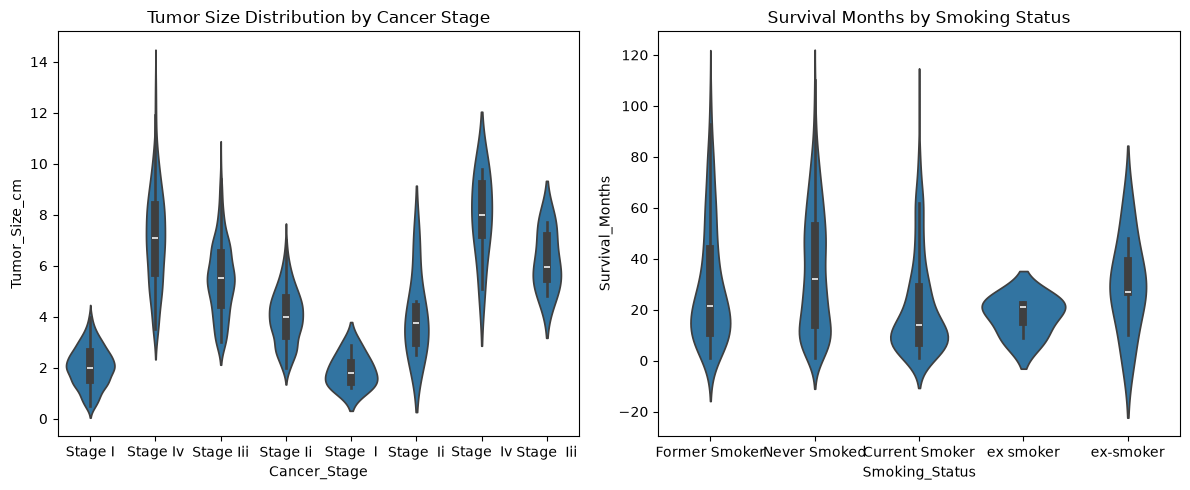

--- Question 6 ---
Shape: (2040, 46)
Column Data Types:
Patient_ID                     str
Diagnosis_Year               int64
Diagnosis_Date                 str
WHO_Region                     str
Country                        str
Age                          int64
Age_Group                      str
Gender                         str
Smoking_Status                 str
Cigarettes_Per_Day           int64
Years_Smoking              float64
Pack_Years                 float64
Secondhand_Smoke               str
Family_History                 str
Occupational_Hazard            str
Air_Pollution_Exposure         str
Alcohol_Use                    str
BMI                        float64
BMI_Category                   str
Exercise_Frequency             str
Chronic_Lung_Disease           str
Asbestos_Exposure              str
Radon_Exposure                 str
Previous_Cancer_History        str
Risk_Factor_Count            int64
Genetic_Mutation               str
Coughing                       str

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# File path definition
file_path = "lung_cancer_dataset_dirty.csv"

# Question 1: Full Cleaning Pipeline
print("--- Question 1 ---")
# Start from fresh raw data
df_raw = pd.read_csv(file_path)

# (a) Drop duplicates
q1_df = df_raw.drop_duplicates().copy()

# (b) Strip whitespace and normalize case
text_cols = q1_df.select_dtypes(include=['object']).columns
for col in text_cols:
    q1_df[col] = q1_df[col].astype(str).str.strip()

cols_to_title = ['Gender', 'WHO_Region', 'BMI_Category', 'Cancer_Stage', 'Treatment']
for col in cols_to_title:
    if col in q1_df.columns:
        q1_df[col] = q1_df[col].str.title()

# Fix Roman numerals in Cancer_Stage
if 'Cancer_Stage' in q1_df.columns:
    replacements = {'I': 'I', 'Ii': 'II', 'Iii': 'III', 'Iv': 'IV'}
    q1_df['Cancer_Stage'] = q1_df['Cancer_Stage'].replace(replacements)

# (c) Convert placeholders to NaN
if 'Tumor_Size_cm' in q1_df.columns:
    q1_df['Tumor_Size_cm'] = q1_df['Tumor_Size_cm'].replace(-1, np.nan)
if 'Alcohol_Use' in q1_df.columns:
    q1_df['Alcohol_Use'] = q1_df['Alcohol_Use'].replace('Unknown', np.nan)

# (d) Linear interpolation for Years_Smoking
if 'Years_Smoking' in q1_df.columns:
    q1_df['Years_Smoking'] = q1_df['Years_Smoking'].interpolate(method='linear')

# (e) Drop rows with missing values in any other column
q1_df = q1_df.dropna()

# (f) Print shape and confirm zero missing values
print(f"Final shape of q1_df: {q1_df.shape}")
print(f"Total missing values remaining: {q1_df.isna().sum().sum()}\n")


# Question 2: Standardizing Inconsistent Category Labels
print("--- Question 2 ---")
print("Before standardization:")
print(q1_df['Smoking_Status'].value_counts())

# Mapping to fix inconsistent categories
def clean_smoking_status(status):
    status = str(status).lower()
    if 'current' in status or status == 'smoker' or 'active' in status:
        return 'Current Smoker'
    elif 'former' in status or 'quit' in status:
        return 'Former Smoker'
    elif 'never' in status or 'non' in status:
        return 'Never Smoked'
    return status

q1_df['Smoking_Status'] = q1_df['Smoking_Status'].apply(clean_smoking_status)

print("\nAfter standardization:")
print(q1_df['Smoking_Status'].value_counts(), "\n")


# Question 3: Descriptive Statistics
print("--- Question 3 ---")
# Compute specific stats for Tumor_Size_cm and BMI
for col in ['Tumor_Size_cm', 'BMI']:
    print(f"Stats for {col}:")
    print(f"Mean: {q1_df[col].mean():.2f}")
    print(f"Median: {q1_df[col].median():.2f}")
    print(f"Std Dev: {q1_df[col].std():.2f}")
    print(f"Min: {q1_df[col].min():.2f}")
    print(f"Max: {q1_df[col].max():.2f}\n")

# Full numeric summary
print("Full statistical summary of numeric columns:")
print(q1_df.describe(), "\n")


# Question 4: Group By and Aggregate
print("--- Question 4 ---")
agg_df = q1_df.groupby(['Cancer_Stage', 'Smoking_Status']).agg(
    n_patients=('Cancer_Stage', 'count'),
    avg_Survival_Months=('Survival_Months', 'mean'),
    avg_Tumor_Size_cm=('Tumor_Size_cm', 'mean')
).reset_index()

print(agg_df)
# To find the lowest average survival
lowest_survival = agg_df.loc[agg_df['avg_Survival_Months'].idxmin()]
print(f"\nThe combination with the lowest average survival is Stage {lowest_survival['Cancer_Stage']} - {lowest_survival['Smoking_Status']}.\n")


# Question 5: Visualize with Violin Plots
plt.figure(figsize=(12, 5))

# (a) Tumor_Size_cm across Cancer_Stage
plt.subplot(1, 2, 1)
sns.violinplot(data=q1_df, x='Cancer_Stage', y='Tumor_Size_cm')
plt.title('Tumor Size Distribution by Cancer Stage')

# (b) Survival_Months across Smoking_Status
plt.subplot(1, 2, 2)
sns.violinplot(data=q1_df, x='Smoking_Status', y='Survival_Months')
plt.title('Survival Months by Smoking Status')

plt.tight_layout()
plt.show()


# Question 6: Data Loading & Initial Inspection
print("--- Question 6 ---")
df_fresh = pd.read_csv(file_path)
print(f"Shape: {df_fresh.shape}")
print("Column Data Types:")
print(df_fresh.dtypes)
print("First 5 rows:")
print(df_fresh.head())

mem_usage = df_fresh.memory_usage(deep=True) / (1024 * 1024)
print("\nMemory Usage in MB:")
print(mem_usage)
max_mem_col = mem_usage.idxmax()
print(f"\nColumn using the most memory: {max_mem_col}")


# Question 7: Fixing Placeholder Values with replace()
print("\n--- Question 7 ---")
df_q7 = pd.read_csv(file_path)

# (a) Show isna().sum() and count actual placeholders
missing_detected_tumor = df_q7['Tumor_Size_cm'].isna().sum()
missing_detected_alcohol = df_q7['Alcohol_Use'].isna().sum()

actual_neg_1 = (df_q7['Tumor_Size_cm'] == -1).sum()
actual_unknown = (df_q7['Alcohol_Use'] == 'Unknown').sum()

print(f"Initial NaNs in Tumor_Size_cm: {missing_detected_tumor}. Count of -1: {actual_neg_1}")
print(f"Initial NaNs in Alcohol_Use: {missing_detected_alcohol}. Count of 'Unknown': {actual_unknown}")

# (b) Use replace
df_q7['Tumor_Size_cm'] = df_q7['Tumor_Size_cm'].replace(-1, np.nan)
df_q7['Alcohol_Use'] = df_q7['Alcohol_Use'].replace('Unknown', np.nan)

# (c) Confirm missing values increased
print(f"New NaNs in Tumor_Size_cm: {df_q7['Tumor_Size_cm'].isna().sum()}")
print(f"New NaNs in Alcohol_Use: {df_q7['Alcohol_Use'].isna().sum()}\n")


# Question 8: Advanced Interpolation
print("--- Question 8 ---")
df_q8 = pd.read_csv(file_path).sort_values(by='Diagnosis_Year')
bmi_series = df_q8['BMI'].head(15).reset_index(drop=True).copy()

# Introduce artificial NaNs
bmi_series.iloc[[2, 3, 10]] = np.nan
print("Original Series with artificial NaNs:")
print(bmi_series.values)

print("\n(a) limit=1")
print(bmi_series.interpolate(method='linear', limit=1).values)

print("\n(b) limit_direction='both'")
# Putting a NaN at the very start to demonstrate 'both' direction
bmi_series.iloc[0] = np.nan
print(bmi_series.interpolate(method='linear', limit_direction='both').values)

print("\n(c) Methods comparison")
print("Linear:", bmi_series.interpolate(method='linear').values)
print("Pchip:", bmi_series.interpolate(method='pchip').values)
print("Akima:", bmi_series.interpolate(method='akima').values)


# Question 9: Feature Engineering, Encoding, and Scaling
print("\n--- Question 9 ---")
# (a) Engineer Pack_Years_Per_Year_Smoking
q1_df['Pack_Years_Per_Year_Smoking'] = np.where(
    q1_df['Years_Smoking'] == 0, 
    0, 
    q1_df['Pack_Years'] / q1_df['Years_Smoking']
)

# (b) One-hot encode Cancer_Type
q1_df = pd.get_dummies(q1_df, columns=['Cancer_Type'], drop_first=False)

# (c) Min-Max scaling for Tumor_Size_cm
min_val = q1_df['Tumor_Size_cm'].min()
max_val = q1_df['Tumor_Size_cm'].max()
q1_df['Tumor_Size_Scaled'] = (q1_df['Tumor_Size_cm'] - min_val) / (max_val - min_val)

print("First 5 rows with new columns:")
cols_to_show = ['Pack_Years', 'Years_Smoking', 'Pack_Years_Per_Year_Smoking', 'Tumor_Size_cm', 'Tumor_Size_Scaled']
# Grab the newly created Cancer_Type dummies dynamically
dummy_cols = [c for c in q1_df.columns if c.startswith('Cancer_Type_')]
print(q1_df[cols_to_show + dummy_cols].head(), "\n")


# Question 10: Pivot Tables, Ranking, and Cumulative
print("--- Question 10 ---")
# (a) Pivot table
pivot_tb = pd.pivot_table(q1_df, values='Survival_Months', index='Cancer_Stage', columns='Gender', aggfunc='mean')
print("Pivot Table:")
print(pivot_tb)

# (b) Rank patients by tumor size
q1_df['Tumor_Size_Rank'] = q1_df.groupby('Cancer_Stage')['Tumor_Size_cm'].rank(ascending=False, method='min')

# (c) Cumulative sum of Survival_Months
q1_df = q1_df.sort_values(by='Diagnosis_Year')
q1_df['Cumulative_Survival_Months'] = q1_df['Survival_Months'].cumsum()

print(q1_df[['Diagnosis_Year', 'Survival_Months', 'Cumulative_Survival_Months']].head())